# FXS / 07 — Previous vs new signals vs everything combined (2020 → 2026-11)

Iván (2026-11-11): trade the signals found by the 2021–2025 rediscovery (06) as a portfolio, compare with the previous portfolio, then combine both.

| Set | Signals (every trading day, time exits only, news days included) |
|---|---|
| **PREVIOUS** (03b) | EURUSD-02 sell 04:00→08:00 NY · USDJPY-01 sell 00:55→01:55 UTC · USDJPY-02 buy 00:25→00:55 UTC |
| **NEW** (06, 2021–2025 discovery) | N-EU-1 EURUSD sell 07:45→08:00 NY · N-UJ-1 USDJPY sell 00:55→01:10 UTC · N-UJ-2 USDJPY buy 00:25→00:55 UTC (= USDJPY-02) · N-UJ-3 USDJPY buy 15:20→16:20 NY · N-EJ-1 EURJPY buy 14:55→16:55 NY · N-EJ-2 EURJPY sell 06:00→08:00 NY |
| **ALL** | PREVIOUS + NEW, with USDJPY-02 counted once (8 signals) |

**What each period means**

| Period | PREVIOUS | NEW |
|---|---|---|
| 2020 | found in 2016–2020 (in sample) | not used to find them (but 2016–2020 was scanned in 06) |
| 2021–2025 | the confirmation years (used to pick the set) | **in sample**: these signals were found here |
| 2026 | seen in FXS 05/06 | **unseen** for N-UJ-3 and N-EJ-2 (new windows); partly seen for the others (overlapping windows were tested on 2026) |

Fills at the quoted Dukascopy bid/ask × `SPREAD_FACTOR`, plus `COMMISSION_PER_LOT` per lot round trip. Account: $6,000, size = L × current equity per signal (overlapping signals on the same pair are separate positions).

In [1]:
import json, os, sys, tempfile
import datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

E0 = 6_000.0
LEVERAGES = [1, 2, 3, 5, 10]
COMMISSION_PER_LOT = 3.0
SPREAD_FACTOR = 0.9
WINDOWS = ((dt.date(2020, 1, 1), dt.date(2020, 12, 31), "discovery"), (dt.date(2021, 1, 1), dt.date(2025, 12, 31), "confirmation"),
           (dt.date(2026, 1, 1), dt.date(2026, 11, 6), "holdout"))
PERIODS = {"2020": (2020, 2020), "2021-2025": (2021, 2025), "2026": (2026, 2026)}
# id: (pair, clock, start slot, end slot, direction); NY slots count minutes from 17:00 New York
SIGNALS = {
    "EURUSD-02": ("EURUSD", "NY", 660, 900, -1), "USDJPY-01": ("USDJPY", "UTC", 55, 115, -1), "USDJPY-02": ("USDJPY", "UTC", 25, 55, 1),
    "N-EU-1": ("EURUSD", "NY", 885, 900, -1), "N-UJ-1": ("USDJPY", "UTC", 55, 70, -1), "N-UJ-3": ("USDJPY", "NY", 1340, 1400, 1),
    "N-EJ-1": ("EURJPY", "NY", 1315, 1435, 1), "N-EJ-2": ("EURJPY", "NY", 780, 900, -1)}
SETS = {"PREVIOUS": ["EURUSD-02", "USDJPY-01", "USDJPY-02"],
        "NEW": ["N-EU-1", "N-UJ-1", "USDJPY-02", "N-UJ-3", "N-EJ-1", "N-EJ-2"],
        "ALL": ["EURUSD-02", "USDJPY-01", "USDJPY-02", "N-EU-1", "N-UJ-1", "N-UJ-3", "N-EJ-1", "N-EJ-2"]}

SYNTHETIC = os.environ.get("FXS_SYNTHETIC") == "1"
if SYNTHETIC:
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("FXS_SYNTH_DIR") or tempfile.mkdtemp(prefix="fxs07_")
    os.environ.pop("DUKASCOPY_DIR", None)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import fx_seasonality as F

cfg = F.FXSConfig()
OUT = Path.cwd() / ("07_synthetic" if SYNTHETIC else "07"); OUT.mkdir(exist_ok=True)
cand = pd.DataFrame([{"id": k, "pair": p, "clock": c, "start": s, "end": e, "direction": d} for k, (p, c, s, e, d) in SIGNALS.items()])
cand["rule"] = [f"{'buy' if d > 0 else 'sell'} {r['pair']} {F.slot_label(r['clock'], r['start'])} -> {F.slot_label(r['clock'], r['end']).split()[1]}"
                for (_, r), d in zip(cand.iterrows(), cand["direction"])]
display(cand[["id", "rule"]])
pd.set_option("display.width", 220, "display.max_columns", 40)

,id,rule
0,EURUSD-02,sell EURUSD NY 04:00 -> 08:00
1,USDJPY-01,sell USDJPY UTC 00:55 -> 01:55
2,USDJPY-02,buy USDJPY UTC 00:25 -> 00:55
3,N-EU-1,sell EURUSD NY 07:45 -> 08:00
4,N-UJ-1,sell USDJPY UTC 00:55 -> 01:10
5,N-UJ-3,buy USDJPY NY 15:20 -> 16:20
6,N-EJ-1,buy EURJPY NY 14:55 -> 16:55
7,N-EJ-2,sell EURJPY NY 06:00 -> 08:00


## 0. Synthetic inputs (smoke run only)

In [2]:
if SYNTHETIC:
    base = Path(os.environ["EQUITY_TRADING_DIR"]) / "Dukascopy"
    for i, p in enumerate(("EURUSD", "USDJPY", "EURJPY")):
        F.write_synthetic_candles(base, p, dt.date(2019, 12, 28), dt.date(2026, 11, 6), seed=41 + i, drift_bps=-3.0 if p == "EURUSD" else 0.0,
                                  drift_ny=(4, 8), price=150.0 if p.endswith("JPY") else 1.10)

## 1. Daily results per signal

In [3]:
for p in sorted(set(cand["pair"])):
    for a, b, _ in WINDOWS:
        cov = F.file_coverage(p, a, b)
        assert cov["share"] >= cfg.min_file_share, f"{p} {a.year}: only {cov['share']:.1%} of day files"
parts = [F.structure_detail(cand, a, b, st, cfg, with_price=True, spread_factor=SPREAD_FACTOR) for a, b, st in WINDOWS]
G = pd.concat([x[0] for x in parts]).sort_index().fillna(0.0)
M = pd.concat([x[1] for x in parts]).sort_index().fillna(0.0)
P = pd.concat([x[2] for x in parts]).sort_index().ffill().bfill()
PAIR_OF = cand.set_index("id")["pair"]
comm = pd.Series({i: F.commission_bps_per_lot(PAIR_OF[i], COMMISSION_PER_LOT) for i in G.columns})
N = G - comm
traded = G != 0
pips = pd.DataFrame({i: F.bps_to_pips(N[i], P[i], PAIR_OF[i]) for i in G.columns}, index=G.index).where(traded)
usd = pd.DataFrame({i: pips[i] * F.usd_per_pip_per_lot(PAIR_OF[i], P[i]) for i in G.columns}, index=G.index)
year = pips.index.year
rows = []
for i in cand["id"]:
    r = {"signal": i, "rule": cand.set_index("id").loc[i, "rule"]}
    for per, (a, b) in PERIODS.items():
        x = pips[i][(year >= a) & (year <= b)].dropna()
        r[f"{per} net pips"] = x.mean(); r[f"{per} t"] = x.mean() / (x.std() / np.sqrt(len(x))) if len(x) > 2 else np.nan
    x = pips[i].dropna()
    r.update({"all net pips": x.mean(), "win rate": (x > 0).mean(), "USD per 1-lot trade": usd[i].mean(), "swing pips": x.std()})
    rows.append(r)
sig = pd.DataFrame(rows).set_index("signal")
display(sig.round(2)); sig.to_csv(OUT / "07_signals.csv")
yr = pips.groupby(year).mean()
display(yr.round(2)); yr.to_csv(OUT / "07_signals_yearly_pips.csv")

,rule,2020 net pips,2020 t,2021-2025 net pips,2021-2025 t,2026 net pips,2026 t,all net pips,win rate,USD per 1-lot trade,swing pips
signal,,,,,,,,,,,
EURUSD-02,sell EURUSD NY 04:00 -> 08:00,0.58,0.35,1.56,2.63,0.73,0.66,1.31,0.53,13.12,21.74
USDJPY-01,sell USDJPY UTC 00:55 -> 01:55,3.01,2.82,0.98,1.90,-0.68,-0.62,1.07,0.53,8.49,18.15
USDJPY-02,buy USDJPY UTC 00:25 -> 00:55,0.58,0.90,0.80,2.12,-0.22,-0.18,0.64,0.53,5.09,13.81
N-EU-1,sell EURUSD NY 07:45 -> 08:00,-1.17,-2.35,0.55,3.11,0.34,1.05,0.27,0.52,2.72,6.50
N-UJ-1,sell USDJPY UTC 00:55 -> 01:10,0.14,0.36,0.70,2.40,-0.32,-0.52,0.49,0.50,3.37,9.87
N-UJ-3,buy USDJPY NY 15:20 -> 16:20,-1.73,-3.36,0.82,3.18,0.11,0.14,0.36,0.50,1.77,9.40
N-EJ-1,buy EURJPY NY 14:55 -> 16:55,-0.37,-0.45,0.74,1.66,0.07,0.07,0.49,0.50,3.41,15.56
N-EJ-2,sell EURJPY NY 06:00 -> 08:00,-1.74,-1.34,0.78,1.20,0.60,0.32,0.39,0.49,2.52,23.59


,EURUSD-02,USDJPY-01,USDJPY-02,N-EU-1,N-UJ-1,N-UJ-3,N-EJ-1,N-EJ-2
2020,0.58,3.01,0.58,-1.17,0.14,-1.73,-0.37,-1.74
2021,1.85,0.46,0.89,0.87,0.02,-0.54,-0.67,0.48
2022,4.20,1.83,2.23,1.06,1.67,1.23,1.65,2.48
2023,1.29,0.38,0.08,0.92,0.73,0.74,1.05,0.36
2024,0.28,0.88,0.96,0.06,0.68,0.75,0.90,-2.64
2025,0.16,1.35,-0.17,-0.15,0.42,1.92,0.75,3.21
2026,0.73,-0.68,-0.22,0.34,-0.32,0.11,0.07,0.60


## 2. How the sets move together

Daily USD result per set at 1 lot per signal, and the correlation between PREVIOUS and NEW.

In [4]:
day_usd = {s: usd[ids].fillna(0).sum(axis=1) for s, ids in SETS.items()}
dd = pd.DataFrame(day_usd)
print("correlation of daily USD results:"); display(dd.corr().round(2))
display(pd.DataFrame({s: {"mean USD/day (1 lot each)": dd[s].mean(), "st.dev USD/day": dd[s].std(),
                          "mean / st.dev": dd[s].mean() / dd[s].std(), "worst day USD": dd[s].min()} for s in SETS}).T.round(2))
display(pd.DataFrame(usd).fillna(0).corr().round(2))

correlation of daily USD results:


,PREVIOUS,NEW,ALL
PREVIOUS,1.00,0.43,0.82
NEW,0.43,1.00,0.84
ALL,0.82,0.84,1.00


,mean USD/day (1 lot each),st.dev USD/day,mean / st.dev,worst day USD
PREVIOUS,26.70,284.48,0.09,-1764.23
NEW,18.88,286.95,0.07,-2870.81
ALL,40.49,443.59,0.09,-2975.65


,EURUSD-02,USDJPY-01,USDJPY-02,N-EU-1,N-UJ-1,N-UJ-3,N-EJ-1,N-EJ-2
EURUSD-02,1.00,0.01,0.09,0.28,0.01,-0.02,-0.01,0.37
USDJPY-01,0.01,1.00,0.07,-0.03,0.53,-0.06,-0.03,-0.00
USDJPY-02,0.09,0.07,1.00,0.03,0.06,-0.10,-0.02,0.07
N-EU-1,0.28,-0.03,0.03,1.00,-0.03,0.01,0.01,0.25
N-UJ-1,0.01,0.53,0.06,-0.03,1.00,0.00,-0.01,0.01
N-UJ-3,-0.02,-0.06,-0.10,0.01,0.00,1.00,0.39,0.02
N-EJ-1,-0.01,-0.03,-0.02,0.01,-0.01,0.39,1.00,0.05
N-EJ-2,0.37,-0.00,0.07,0.25,0.01,0.02,0.05,1.00


## 3. The $6,000 compounding account, 2020 → 2026

,set,signals,L each,final_equity,cagr %,sharpe,max drawdown %,worst year %,worst day % (all open at worst)
0,PREVIOUS,3,1,9147,6.4,1.52,-4.8,0.1,-2.1
1,PREVIOUS,3,2,14182,13.4,1.50,-10.3,0.0,-4.2
2,PREVIOUS,3,3,21582,20.6,1.50,-15.4,-0.1,-6.3
3,PREVIOUS,3,5,48575,35.7,1.50,-24.8,-0.7,-10.5
4,PREVIOUS,3,10,293793,76.6,1.50,-45.2,-4.0,-21.2
5,NEW,6,1,8039,4.4,1.08,-13.6,-8.1,-3.7
6,NEW,6,2,10898,9.1,1.07,-26.6,-17.0,-7.3
7,NEW,6,3,14715,14.0,1.08,-37.6,-24.8,-11.0
8,NEW,6,5,25121,23.3,1.07,-55.3,-39.1,-18.9
9,NEW,6,10,78817,45.7,1.08,-80.8,-64.7,-37.8


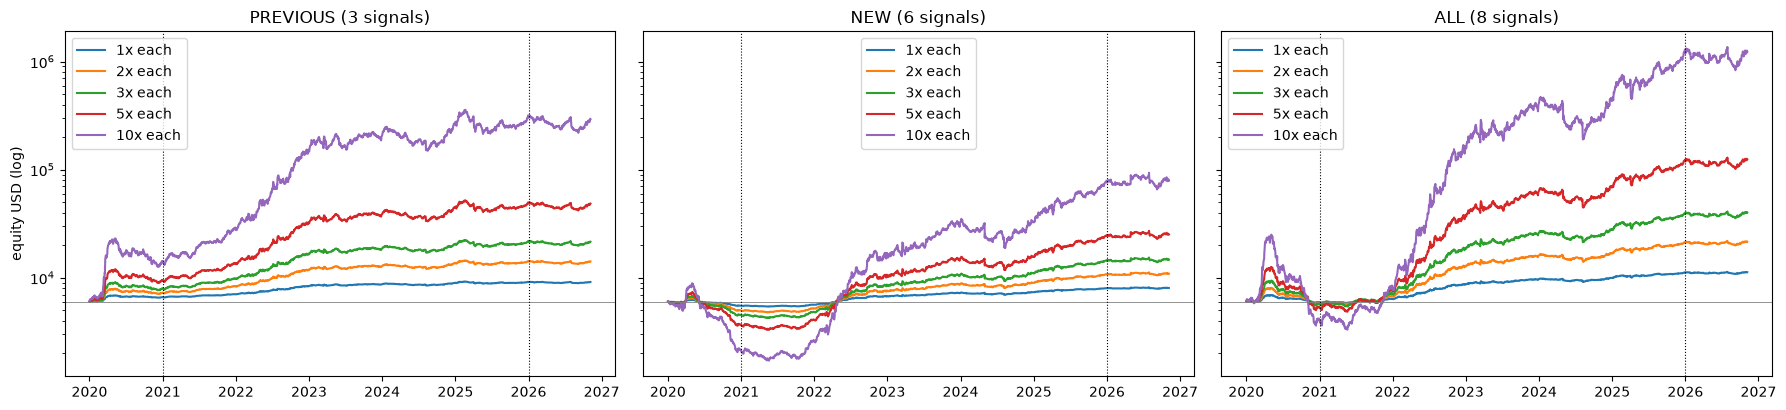

In [5]:
rows, curves = [], {}
for s, ids in SETS.items():
    for L in LEVERAGES:
        acc = F.simulate_account(N[ids], pd.Series(float(L), index=ids), E0)
        curves[(s, L)] = acc
        prev = acc["equity"].shift(1).fillna(E0).to_numpy()
        units = np.floor(prev[:, None] * L / 1000) * 1000
        worst = ((units * (M[ids].to_numpy() - comm[ids].to_numpy())).sum(axis=1) / 1e4 / np.maximum(prev, 1e-9)).min()
        st = F.account_stats(acc, E0)
        rows.append({"set": s, "signals": len(ids), "L each": L, "final_equity": round(st["final_equity"]), "cagr %": round(100 * st["cagr"], 1),
                     "sharpe": round(st["sharpe"], 2), "max drawdown %": round(100 * st["max_drawdown"], 1),
                     "worst year %": round(100 * st["worst_year"], 1), "worst day % (all open at worst)": round(100 * worst, 1)})
acc_tab = pd.DataFrame(rows)
display(acc_tab); acc_tab.to_csv(OUT / "07_account.csv", index=False)
fig, axes = plt.subplots(1, len(SETS), figsize=(18, 4.2), sharey=True)
for ax, s in zip(axes, SETS):
    for L in LEVERAGES:
        ax.plot(curves[(s, L)]["equity"].clip(lower=1), label=f"{L}x each")
    ax.axhline(E0, color="grey", lw=0.6)
    for b_ in ("2021-01-01", "2026-01-01"):
        ax.axvline(pd.Timestamp(b_), color="black", ls=":", lw=0.8)
    ax.set_yscale("log"); ax.set_title(f"{s} ({len(SETS[s])} signals)"); ax.legend()
axes[0].set_ylabel("equity USD (log)")
plt.tight_layout(); plt.savefig(OUT / "07_equity.png", dpi=110); plt.show()

## 4. Each period on its own (separate $6,000 accounts)

In [6]:
pr = []
for s, ids in SETS.items():
    for per, (a, b) in PERIODS.items():
        sel = (N.index.year >= a) & (N.index.year <= b)
        for L in LEVERAGES:
            st = F.account_stats(F.simulate_account(N.loc[sel, ids], pd.Series(float(L), index=ids), E0), E0)
            pr.append({"set": s, "period": per, "L": L, "cagr %": round(100 * st["cagr"], 1), "max dd %": round(100 * st["max_drawdown"], 1)})
pr = pd.DataFrame(pr)
display(pr.pivot_table(index=["set", "L"], columns="period", values=["cagr %", "max dd %"])[[("cagr %", p) for p in PERIODS] + [("max dd %", p) for p in PERIODS]])
pr.to_csv(OUT / "07_period_account.csv", index=False)

cagr %                max dd %                
period        2020 2021-2025 2026     2020 2021-2025  2026
set      L                                                
ALL      1    -1.1      13.4  0.9    -15.2      -6.9  -4.3
         2    -2.7      29.4  2.3    -29.5     -14.3  -8.8
         3    -4.4      47.0  3.6    -41.4     -21.4 -13.0
         5   -10.8      86.8  4.6    -60.2     -34.0 -21.1
         10  -31.6     213.6  0.7    -85.6     -59.6 -38.8
NEW      1    -8.1       7.9  0.3    -12.2      -4.6  -3.2
         2   -17.0      16.8  1.2    -24.0     -10.1  -6.4
         3   -24.9      26.4  2.0    -34.4     -15.0  -9.6
         5   -39.2      46.9  2.8    -51.2     -24.5 -15.8
         10  -64.8     106.6  2.1    -76.9     -46.0 -29.8
PREVIOUS 1    10.2       6.7 -0.2     -4.8      -4.6  -3.0
         2    21.1      14.3 -0.3    -10.3      -9.2  -6.6
         3    32.5      22.0 -0.6    -15.4     -13.6  -9.9
         5    58.6      38.8 -0.9    -24.8     -22.0 -15.9
         10  136.5      85.0 -4.8    -45.2     -40.2 -30.9

## 5. Year by year (account return %, 2× each)

In [7]:
yrs = {}
for s in SETS:
    e = curves[(s, 2)]["equity"].resample("YE").last()
    r = e.pct_change(); r.iloc[0] = e.iloc[0] / E0 - 1; r.index = r.index.year
    yrs[s] = 100 * r
yrs = pd.DataFrame(yrs)
display(yrs.round(1)); yrs.to_csv(OUT / "07_yearly_returns_2x.csv")

,PREVIOUS,NEW,ALL
2020,21.0,-17.0,-2.7
2021,14.4,4.3,14.8
2022,42.8,46.5,92.4
2023,7.5,15.2,23.3
2024,7.2,2.5,6.5
2025,3.7,19.7,25.3
2026,0.0,1.3,1.9


In [8]:
summary = {"study": "FXS07", "descriptive": True, "synthetic": SYNTHETIC, "signals": {k: list(v) for k, v in SIGNALS.items()}, "sets": SETS,
           "commission_usd_per_lot_rt": COMMISSION_PER_LOT, "spread_factor": SPREAD_FACTOR, "equity0": E0,
           "signals_table": sig.round(4).reset_index().to_dict(orient="records"), "account": acc_tab.to_dict(orient="records"),
           "note": "NEW signals were found on 2021-2025 (in sample there); 2026 is unseen only for N-UJ-3 and N-EJ-2."}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("written", OUT / "summary.json")

written D:\Projects\equity_trading\notebooks\FX_Intraday_Seasonality\Portfolio\07\summary.json
